<div style="background: linear-gradient(135deg, #123b5d, #1f6f8b); color: white; padding: 28px; border-radius: 12px;">
  <h1 style="margin: 0;">GBU 2301: Business Statistics</h1>
  <h2 style="margin: 8px 0 18px 0; font-weight: 400;">Week 9: Interval Estimation</h2>
  <p style="margin: 0; font-size: 1.05em;">Fall 2026 | Dr. Omer Cayirli | Assistant Professor of Finance</p>
</div>

Required reading: Anderson et al., Statistics for Business and Economics, 15th ed., Chapter 8

---


### Outline

* Interval Estimation and Confidence Levels
* Population Mean: $\sigma$ Known
* Population Mean: $\sigma$ Unknown
* Sample Size for Estimating a Mean
* Population Proportion
* Sample Size for Estimating a Proportion
* Big Data and Confidence Intervals

---


### Point and Interval Estimates

Alpha Bottling is evaluating a new production run. Its current population mean fill volume $\mu$ is unknown.

| Sample information | Value |
|---|---:|
| Number of independently sampled bottles, $n$ | 36 |
| Sample mean, $\bar x$ | 497.8 mL |

* Point estimate of $\mu$: $\bar x=497.8$ mL.
* Another sample would generally produce a different mean.
* An interval estimate adds a margin of error to describe sampling uncertainty.

$$\text{Interval estimate}=\text{point estimate}\pm\text{margin of error}.$$

For a mean, write the interval as

$$[\bar x-E,\;\bar x+E].$$

The margin of error $E$ must come from the sampling distribution, not an arbitrary allowance.

---


### Standard Error and Margin of Error

Suppose Alpha Bottling's population standard deviation remains known at $\sigma=12$ mL. Knowing the spread does not tell us the current mean.

For independent observations,

$$\sigma_{\bar X}=\frac{\sigma}{\sqrt n}
=\frac{12}{\sqrt{36}}=2\text{ mL}.$$

| Quantity | Meaning | Alpha Bottling |
|---|---|---:|
| $\sigma$ | Spread of individual fill volumes | 12 mL |
| $\sigma_{\bar X}$ | Spread of sample means across repeated samples | 2 mL |
| $E$ | Distance from the sample mean to either interval endpoint | To be determined |

$$E=\text{critical value}\times\text{standard error}.$$

* The critical value depends on the confidence level.
* The full interval width is $2E$, not $E$.

---


### Confidence Level

Assume independent observations from a normal population, with known $\sigma$.

$$Z=\frac{\bar X-\mu}{\sigma/\sqrt n}\sim N(0,1).$$

For the standard normal distribution,

$$P(-1.96\leq Z\leq1.96)\approx0.95.$$

Therefore,

$$P\left(-1.96\frac{\sigma}{\sqrt n}
\leq\bar X-\mu\leq
1.96\frac{\sigma}{\sqrt n}\right)\approx0.95.$$

* About 95% of sample means lie within $1.96$ standard errors of $\mu$.
* This gives the margin of error $E=1.96\,\sigma/\sqrt n$.
* For Alpha Bottling, $E=1.96(2)=3.92$ mL.

*For a nonnormal population, this reasoning is approximate when the sampling distribution of $\bar X$ is approximately normal.*

---


### Confidence Interval for the Mean

Start with the event

$$-E\leq\bar X-\mu\leq E.$$

Separate the two inequalities:

$$\bar X-\mu\leq E
\quad\Longrightarrow\quad
\mu\geq\bar X-E,$$

$$\bar X-\mu\geq-E
\quad\Longrightarrow\quad
\mu\leq\bar X+E.$$

Combining them gives

$$\bar X-E\leq\mu\leq\bar X+E.$$

Thus, under the normal model,

$$P\left(\bar X-1.96\frac{\sigma}{\sqrt n}
\leq\mu\leq
\bar X+1.96\frac{\sigma}{\sqrt n}\right)\approx0.95.$$

Before sampling, the endpoints vary with $\bar X$; $\mu$ remains fixed.

---


### Interpreting a Confidence Interval

For Alpha Bottling, the observed 95% confidence interval is

$$\bar x\pm E=497.8\pm3.92=[493.88,\;501.72]\text{ mL}.$$

We are 95% confident that the population mean fill volume is between 493.88 and 501.72 mL.

* If we repeatedly sampled and constructed intervals by this method, about 95% would contain the fixed population mean.
* This particular interval either contains $\mu$ or does not. We do not know which.
* It is not an interval containing 95% of individual bottle volumes.
* It does not mean that 95% of future sample means will fall inside these observed endpoints.

**The confidence level describes the method's long-run coverage under its assumptions.**

---


### Confidence Intervals: Repeated Samples

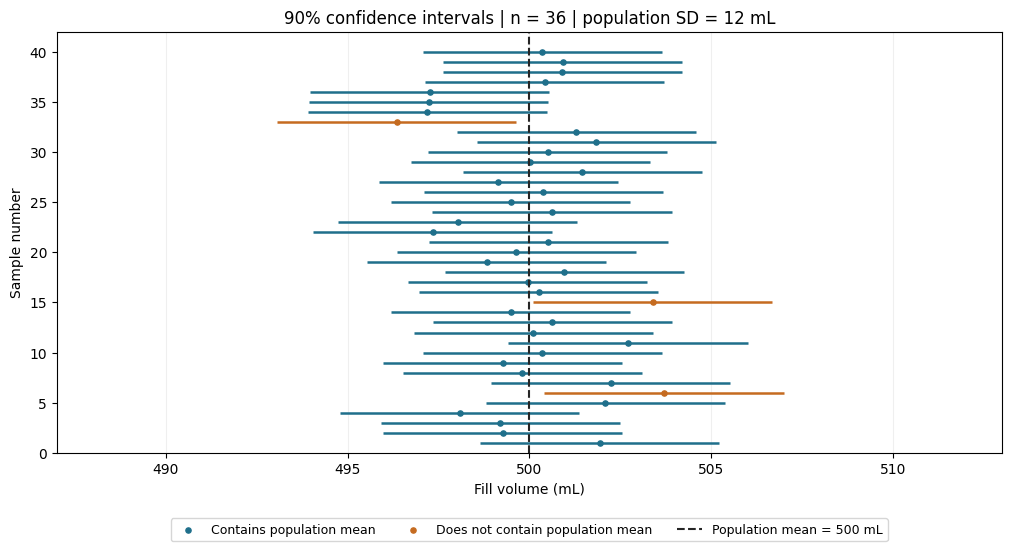

* Intervals containing the mean: 37 of 40 (92.5%); selected confidence level: 90%.
* Each dot is a sample mean; each horizontal line is its confidence interval.
* The population mean is known here only to check coverage in the simulation.
* Changing confidence reuses the same samples. A batch of 40 need not match the long-run coverage exactly.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from scipy.stats import norm
from IPython.display import display, Markdown

def coverage_values(confidence=0.95, seed=230109):
    mu, sigma, n = 500.0, 12.0, 36
    samples = np.random.default_rng(seed).normal(mu, sigma, size=(40, n))
    means = samples.mean(axis=1)
    margin = norm.isf((1 - confidence) / 2) * sigma / np.sqrt(n)
    lower, upper = means - margin, means + margin
    covered = (lower <= mu) & (mu <= upper)
    return means, lower, upper, covered

def confidence_coverage_explorer():
    display(Markdown("### Confidence Intervals: Repeated Samples"))
    level = widgets.Dropdown(
        options=[("90%", 0.90), ("95%", 0.95), ("99%", 0.99)],
        value=0.95, description="Confidence:")
    resample = widgets.Button(description="Draw 40 new samples")
    display(widgets.HBox([level, resample]))
    state = {"seed": 230109}
    graph_handle = text_handle = None

    def update(change=None):
        nonlocal graph_handle, text_handle
        means, lower, upper, covered = coverage_values(level.value, state["seed"])
        fig, ax = plt.subplots(figsize=(10, 5.4), constrained_layout=True)
        row = np.arange(1, 41)
        for mask, color, label in [
            (covered, "#1f6f8b", "Contains population mean"),
            (~covered, "#c56b20", "Does not contain population mean")
        ]:
            ax.hlines(row[mask], lower[mask], upper[mask], color=color, linewidth=1.8)
            ax.scatter(means[mask], row[mask], color=color, s=14, label=label)
        ax.axvline(500, color="#252525", linestyle="--", label="Population mean = 500 mL")
        extent = max(13, 500 - lower.min() + 1, upper.max() - 500 + 1)
        ax.set(xlim=(500 - extent, 500 + extent), ylim=(0, 42), xlabel="Fill volume (mL)",
               ylabel="Sample number",
               title=f"{level.value:.0%} confidence intervals | n = 36 | population SD = 12 mL")
        ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=3, fontsize=9)
        ax.grid(axis="x", alpha=0.2)
        if graph_handle is None:
            graph_handle = display(fig, display_id=True)
        else:
            graph_handle.update(fig)
        plt.close(fig)
        content = Markdown(
            f"* Intervals containing the mean: {covered.sum()} of 40 "
            f"({covered.mean():.1%}); selected confidence level: {level.value:.0%}.\n"
            "* Each dot is a sample mean; each horizontal line is its confidence interval.\n"
            "* The population mean is known here only to check coverage in the simulation.\n"
            "* Changing confidence reuses the same samples. A batch of 40 need not match the long-run coverage exactly."
        )
        if text_handle is None:
            text_handle = display(content, display_id=True)
        else:
            text_handle.update(content)

    def new_samples(button):
        state["seed"] += 1
        update()

    level.observe(update, names="value")
    resample.on_click(new_samples)
    update()
    return level, resample

coverage_controls = confidence_coverage_explorer()


---

### Population Mean: $\sigma$ Known

For confidence level $1-\alpha$,

$$\bar x\pm z_{\alpha/2}\frac{\sigma}{\sqrt n},
\qquad
E=z_{\alpha/2}\frac{\sigma}{\sqrt n}.$$

* $\alpha$: total probability outside the central confidence region.
* $z_{\alpha/2}$: positive standard normal value with upper-tail probability $\alpha/2$.
* $\sigma$: known population standard deviation, not the sample standard deviation.

Conditions:

* A random sample with independent observations, or a simple random sample with a negligible sampling fraction.
* Normal population for an exact normal-theory interval; otherwise, a sufficiently large sample for an approximately normal sample mean.
* If sampling without replacement from a finite population and $n/N>0.05$, account for the finite-population correction discussed earlier.

*The examples below use independent observations from an ongoing process.*

---


### Standard Normal Critical Values

Split the probability outside the central region equally between the two tails:

$$P(Z>z_{\alpha/2})=\frac{\alpha}{2},
\qquad
P(Z\leq z_{\alpha/2})=1-\frac{\alpha}{2}.$$

| Confidence level $1-\alpha$ | $\alpha$ | Upper-tail area $\alpha/2$ | Cumulative area | $z_{\alpha/2}$ |
|---:|---:|---:|---:|---:|
| 90% | 0.10 | 0.05 | 0.950 | 1.645 |
| 95% | 0.05 | 0.025 | 0.975 | 1.960 |
| 99% | 0.01 | 0.005 | 0.995 | 2.576 |

For 95% confidence, look for cumulative area $0.975$, giving $z_{0.025}=1.96$.

Excel: <code>=NORM.S.INV(0.975)</code>

**The subscript is the upper-tail area, not the cumulative area to the left.**

---


### Confidence Interval: Fill Volume

Alpha Bottling samples independent fills from a normal production process.

| Sample size $n$ | Sample mean $\bar x$ | Known population SD $\sigma$ | Confidence level |
|---:|---:|---:|---:|
| 36 | 497.8 mL | 12 mL | 95% |

$$\sigma_{\bar X}=\frac{\sigma}{\sqrt n}
=\frac{12}{\sqrt{36}}=2\text{ mL}.$$

$$E=z_{\alpha/2}\frac{\sigma}{\sqrt n}
=1.96\frac{12}{\sqrt{36}}=3.92\text{ mL}.$$

$$\bar x\pm E=497.8\pm3.92
=[493.88,\;501.72]\text{ mL}.$$

* Point estimate: 497.8 mL; margin of error: 3.92 mL.
* The population mean could be 500 mL: that value is inside the interval.
* Inclusion does not establish that $\mu$ equals 500 mL.

---


### Confidence Level and Interval Width

Keep Alpha Bottling's sample fixed: $\bar x=497.8$ mL, $n=36$, and $\sigma=12$ mL.

$$E=z_{\alpha/2}\frac{\sigma}{\sqrt n}
=z_{\alpha/2}(2),
\qquad
\text{width}=2E.$$

| Confidence level | Margin of error (mL) | Confidence interval (mL) | Width (mL) |
|---:|---:|---|---:|
| 90% | $1.645(2)=3.29$ | $[494.51,\;501.09]$ | 6.58 |
| 95% | $1.960(2)=3.92$ | $[493.88,\;501.72]$ | 7.84 |
| 99% | $2.576(2)=5.152$ | $[492.65,\;502.95]$ | 10.30 |

* Higher confidence requires a wider interval for the same sample.
* The point estimate does not change.
* Greater confidence is not greater precision.

---


### Confidence Interval: Confidence Level and Sample Size

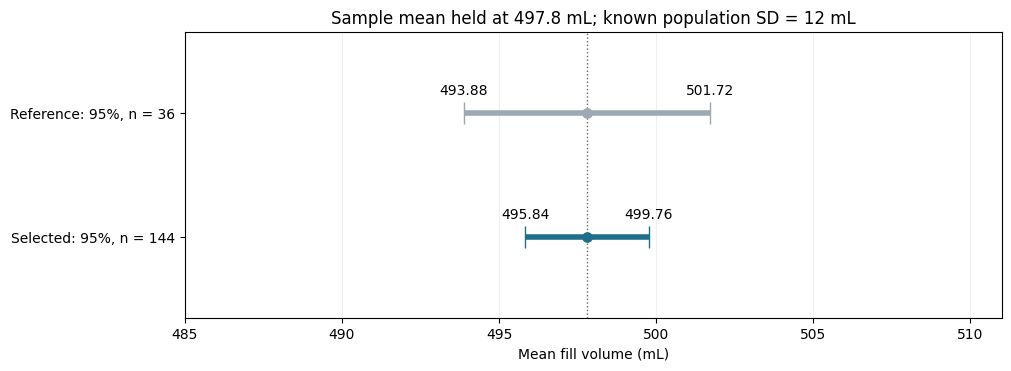

$$E=z_{\alpha/2}\frac{\sigma}{\sqrt n}=1.9600\frac{12}{\sqrt{144}}=1.96\text{ mL},\qquad \text{width}=2E=3.92\text{ mL}.$$

* This comparison holds the sample mean fixed to isolate changes in width. A newly collected sample would generally have a different mean.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from scipy.stats import norm
from IPython.display import display, Markdown

def mean_interval_values(confidence=0.95, n=36, mean=497.8, sigma=12.0):
    z = norm.isf((1 - confidence) / 2)
    se = sigma / np.sqrt(n)
    margin = z * se
    return z, se, margin, mean - margin, mean + margin

def mean_interval_explorer():
    display(Markdown("### Confidence Interval: Confidence Level and Sample Size"))
    level = widgets.Dropdown(
        options=[("90%", 0.90), ("95%", 0.95), ("99%", 0.99)],
        value=0.95, description="Confidence:")
    n_control = widgets.IntSlider(value=144, min=9, max=144, step=1,
                                  description="Sample size:", continuous_update=False,
                                  style={"description_width": "initial"})
    display(widgets.HBox([level, n_control]))
    graph_handle = text_handle = None

    def update(change=None):
        nonlocal graph_handle, text_handle
        z, se, margin, lower, upper = mean_interval_values(level.value, n_control.value)
        base = mean_interval_values()
        fig, ax = plt.subplots(figsize=(10, 3.6), constrained_layout=True)
        for y, lo, hi, color in [
            (1, base[3], base[4], "#9ba9b5"), (0, lower, upper, "#1f6f8b")
        ]:
            ax.hlines(y, lo, hi, color=color, linewidth=4)
            ax.plot([lo, hi], [y, y], "|", color=color, markersize=16)
            ax.scatter([497.8], [y], color=color, s=45, zorder=3)
            ax.annotate(f"{lo:.2f}", (lo, y), xytext=(0, 13),
                        textcoords="offset points", ha="center")
            ax.annotate(f"{hi:.2f}", (hi, y), xytext=(0, 13),
                        textcoords="offset points", ha="center")
        ax.axvline(497.8, color="#666666", linestyle=":", linewidth=1)
        ax.set(xlim=(485, 511), ylim=(-0.65, 1.65), xlabel="Mean fill volume (mL)",
               yticks=[0, 1],
               yticklabels=[f"Selected: {level.value:.0%}, n = {n_control.value}",
                            "Reference: 95%, n = 36"],
               title="Sample mean held at 497.8 mL; known population SD = 12 mL")
        ax.grid(axis="x", alpha=0.2)
        if graph_handle is None:
            graph_handle = display(fig, display_id=True)
        else:
            graph_handle.update(fig)
        plt.close(fig)
        content = Markdown(
            rf"$$E=z_{{\alpha/2}}\frac{{\sigma}}{{\sqrt n}}"
            rf"={z:.4f}\frac{{12}}{{\sqrt{{{n_control.value}}}}}"
            rf"={margin:.2f}\text{{ mL}},\qquad \text{{width}}=2E={2*margin:.2f}\text{{ mL}}.$$"
            "\n\n* This comparison holds the sample mean fixed to isolate changes in width. "
            "A newly collected sample would generally have a different mean."
        )
        if text_handle is None:
            text_handle = display(content, display_id=True)
        else:
            text_handle.update(content)

    level.observe(update, names="value")
    n_control.observe(update, names="value")
    update()
    return level, n_control

mean_interval_controls = mean_interval_explorer()


---

### Sample Size and Interval Width

For a fixed confidence level and population standard deviation,

$$E=z_{\alpha/2}\frac{\sigma}{\sqrt n},
\qquad
\frac{E_2}{E_1}=\sqrt{\frac{n_1}{n_2}}.$$

For Alpha Bottling at 95% confidence, with $\sigma=12$ mL:

| Sample size $n$ | Standard error (mL) | Margin of error (mL) | Width (mL) |
|---:|---:|---:|---:|
| 9 | $12/\sqrt9=4$ | $1.96(4)=7.84$ | 15.68 |
| 36 | $12/\sqrt{36}=2$ | $1.96(2)=3.92$ | 7.84 |
| 144 | $12/\sqrt{144}=1$ | $1.96(1)=1.96$ | 3.92 |

* Multiplying the sample size by four halves the margin of error.
* Increasing sample size improves precision without lowering confidence.
* These comparisons concern interval width, not changes in the population's variability.

---


### Exercise 1

Beta Packing independently samples cartons from a normal production process. The population standard deviation is known.

| Sample size $n$ | Sample mean $\bar x$ | Population SD $\sigma$ |
|---:|---:|---:|
| 64 | 50.6 kg | 4 kg |

a. Calculate a 95% confidence interval for the population mean carton weight.

b. A second report uses the same sample and gives $[49.31,\;51.89]$ kg. Which confidence level, 90%, 95%, or 99%, is consistent with that report? Show your calculation.

c. The sample size is increased to 256. At 95% confidence, calculate the new margin of error. Can you also give the new interval endpoints before seeing the additional observations?

---


### Population Mean: $\sigma$ Unknown

Usually, the population standard deviation is unknown. Estimate it using the same sample:

$$s=\sqrt{\frac{\sum_{i=1}^{n}(x_i-\bar x)^2}{n-1}},
\qquad
s_{\bar x}=\frac{s}{\sqrt n}.$$

* $\bar x$ estimates $\mu$.
* $s$ estimates $\sigma$.
* $s/\sqrt n$ estimates the standard error of the sample mean.

Replacing $\sigma$ by the random sample standard deviation $S$ changes the standardized statistic:

$$Z=\frac{\bar X-\mu}{\sigma/\sqrt n}
\quad\longrightarrow\quad
T=\frac{\bar X-\mu}{S/\sqrt n}.$$

**For independent observations from a normal population, $T$ follows a $t$ distribution with $n-1$ degrees of freedom.**

---


### The $t$ Distribution

The deviations used in the sample variance satisfy

$$\sum_{i=1}^{n}(x_i-\bar x)=0.$$

Example: if three observations have $\bar x=10$ and the first two deviations are $-2$ and $1$, the third must be $1$.

* Once the mean and $n-1$ deviations are fixed, the last deviation is determined.
* The sample variance, and the corresponding $t$ distribution here, have $df=n-1$.

Properties:

* Symmetric around zero, with heavier tails than the standard normal.
* Depends on the degrees of freedom.
* For the same confidence level, a finite-$df$ $t$ critical value exceeds the $z$ critical value.
* As degrees of freedom increase, the $t$ distribution approaches the standard normal.

The heavier tails account for estimating $\sigma$ with $s$.

---


### The t Distribution and the Standard Normal

IntSlider(value=7, continuous_update=False, description='Degrees of freedom:', min=1, style=SliderStyle(descri…

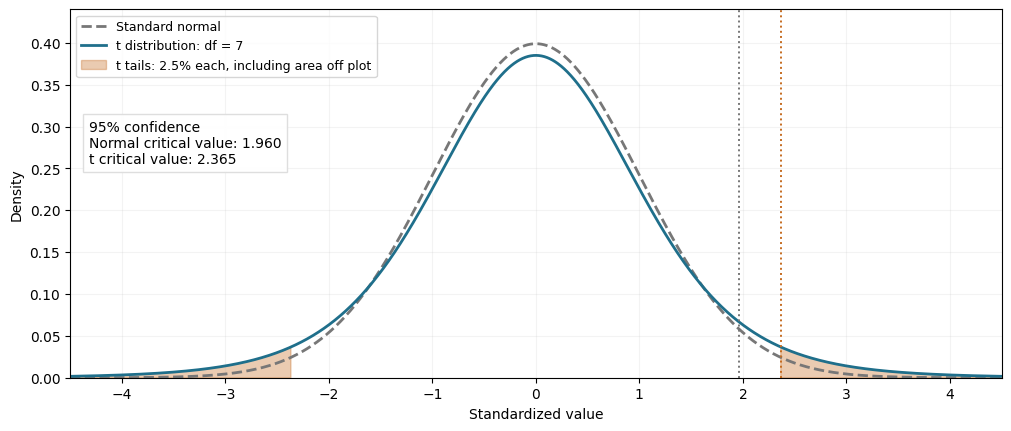

$$P(-2.365\leq T\leq 2.365)\approx0.95,\qquad df=7,\quad n=8.$$

* At the same confidence level and standard-error value, the larger critical value produces a wider interval.

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from scipy.stats import norm, t
from IPython.display import display, Markdown

def t_critical_values(df, confidence=0.95):
    alpha = 1 - confidence
    return norm.isf(alpha / 2), t.isf(alpha / 2, df)

def t_distribution_explorer():
    display(Markdown("### The t Distribution and the Standard Normal"))
    df_control = widgets.IntSlider(value=7, min=1, max=100, step=1,
                                   description="Degrees of freedom:",
                                   continuous_update=False,
                                   style={"description_width": "initial"})
    display(df_control)
    graph_handle = text_handle = None

    def update(change=None):
        nonlocal graph_handle, text_handle
        df = df_control.value
        zcrit, tcrit = t_critical_values(df)
        extent = max(4.5, 1.15 * tcrit)
        x = np.linspace(-extent, extent, 2401)
        fig, ax = plt.subplots(figsize=(10, 4.2), constrained_layout=True)
        ax.plot(x, norm.pdf(x), color="#777777", linestyle="--", linewidth=2,
                label="Standard normal")
        ax.plot(x, t.pdf(x, df), color="#1f6f8b", linewidth=2,
                label=f"t distribution: df = {df}")
        ax.fill_between(x, 0, t.pdf(x, df), where=np.abs(x) >= tcrit,
                        color="#c56b20", alpha=0.35,
                        label="t tails: 2.5% each, including area off plot")
        ax.axvline(zcrit, color="#777777", linestyle=":", linewidth=1.4)
        ax.axvline(tcrit, color="#c56b20", linestyle=":", linewidth=1.4)
        ax.text(0.02, 0.70,
                f"95% confidence\nNormal critical value: {zcrit:.3f}\n"
                f"t critical value: {tcrit:.3f}",
                transform=ax.transAxes, ha="left", va="top",
                bbox={"facecolor": "white", "edgecolor": "#dddddd", "alpha": 0.95})
        ax.set(xlim=(-extent, extent), ylim=(0, 0.44),
               xlabel="Standardized value", ylabel="Density")
        ax.legend(loc="upper left", fontsize=9)
        ax.grid(alpha=0.15)
        if graph_handle is None:
            graph_handle = display(fig, display_id=True)
        else:
            graph_handle.update(fig)
        plt.close(fig)
        content = Markdown(
            rf"$$P(-{tcrit:.3f}\leq T\leq {tcrit:.3f})\approx0.95,"
            rf"\qquad df={df},\quad n={df+1}.$$"
            "\n\n* At the same confidence level and standard-error value, "
            "the larger critical value produces a wider interval."
        )
        if text_handle is None:
            text_handle = display(content, display_id=True)
        else:
            text_handle.update(content)

    df_control.observe(update, names="value")
    update()
    return df_control

t_distribution_control = t_distribution_explorer()


---

### $t$ Critical Values

For confidence level $1-\alpha$, use the positive value $t_{\alpha/2}$ satisfying

$$P(T>t_{\alpha/2})=\frac{\alpha}{2},
\qquad df=n-1.$$

The degrees of freedom identify the row; the upper-tail area identifies the column.

| Degrees of freedom | Upper tail 0.05: 90% CI | Upper tail 0.025: 95% CI | Upper tail 0.005: 99% CI |
|---:|---:|---:|---:|
| 5 | 2.015 | 2.571 | 4.032 |
| 7 | 1.895 | 2.365 | 3.499 |
| 9 | 1.833 | 2.262 | 3.250 |
| 15 | 1.753 | 2.131 | 2.947 |
| 30 | 1.697 | 2.042 | 2.750 |
| $\infty$: standard normal | 1.645 | 1.960 | 2.576 |

For $n=8$ and 95% confidence: $df=7$, $\alpha/2=0.025$, so $t_{0.025}=2.365$.

Excel: <code>=T.INV.2T(0.05,7)</code>. The first argument is the total area in both tails.

---


### Population Mean: $t$ Confidence Interval

Under independent normal sampling,

$$P\left(-t_{\alpha/2}\leq
\frac{\bar X-\mu}{S/\sqrt n}
\leq t_{\alpha/2}\right)=1-\alpha,
\qquad df=n-1.$$

Multiply by $S/\sqrt n>0$:

$$-t_{\alpha/2}\frac S{\sqrt n}
\leq\bar X-\mu
\leq t_{\alpha/2}\frac S{\sqrt n}.$$

Solve the two inequalities for $\mu$:

$$\bar X-t_{\alpha/2}\frac S{\sqrt n}
\leq\mu\leq
\bar X+t_{\alpha/2}\frac S{\sqrt n}.$$

After observing the sample, the confidence interval is

$$\bar x\pm t_{\alpha/2}\frac{s}{\sqrt n},
\qquad E=t_{\alpha/2}\frac{s}{\sqrt n}.$$

*Use $t$ when $\sigma$ is unknown, including large samples. A large $n$ makes $t$ close to $z$; it does not make $\sigma$ known.*

---


### Confidence Interval: Service Time

Gamma Service samples eight independent service times under unchanged operating conditions. Assume the population is approximately normal; $\sigma$ is unknown.

| Observation | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| Time (minutes) | 12 | 9 | 15 | 10 | 14 | 11 | 13 | 12 |

Estimate the population mean service time with 95% confidence.

$$\bar x=\frac{\sum x_i}{n}
=\frac{12+9+15+10+14+11+13+12}{8}
=\frac{96}{8}=12\text{ minutes}.$$

| $x_i$ | 12 | 9 | 15 | 10 | 14 | 11 | 13 | 12 | Total |
|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| $x_i-\bar x$ | 0 | -3 | 3 | -2 | 2 | -1 | 1 | 0 | 0 |
| $(x_i-\bar x)^2$ | 0 | 9 | 9 | 4 | 4 | 1 | 1 | 0 | 28 |

---


### Confidence Interval: Service Time

Using $\bar x=12$, $n=8$, and $\sum(x_i-\bar x)^2=28$,

$$s^2=\frac{\sum(x_i-\bar x)^2}{n-1}
=\frac{28}{7}=4\text{ minutes}^2,
\qquad s=\sqrt4=2\text{ minutes}.$$

$$s_{\bar x}=\frac{s}{\sqrt n}
=\frac2{\sqrt8}\approx0.7071\text{ minutes}.$$

At 95% confidence, $df=8-1=7$ and $t_{0.025}\approx2.365$.

$$E=t_{\alpha/2}\frac{s}{\sqrt n}
=2.365\frac2{\sqrt8}\approx1.67\text{ minutes}.$$

$$\bar x\pm E=12\pm1.67=[10.33,\;13.67]\text{ minutes}.$$

* We are 95% confident that the population mean service time is between 10.33 and 13.67 minutes.
* These are limits for the mean, not limits for individual service times.

---


### Conditions for a Mean Confidence Interval

| Sampling situation | Implication |
|---|---|
| Independent observations from a normal population | Normal-theory $z$ interval or $t$ interval applies, according to whether $\sigma$ is known |
| Small sample from an approximately normal population | A $t$ interval can be reasonable when $\sigma$ is unknown |
| Small sample with strong skewness or extreme outliers | The usual interval may be unreliable |
| Large independent random sample with finite variance | The sample mean is often approximately normal; strong skewness may require a larger sample |
| Dependent observations or a biased selection process | The usual standard error or interpretation may be inappropriate |

* $n\geq30$ is a guideline, not a guarantee.
* Eight reasonably balanced observed values do not prove that a population is normal; the service-time example states the population assumption.
* More observations do not repair a biased selection method.
* For substantial sampling without replacement, the finite-population adjustment still matters.

---


### Exercise 2

Delta Service independently samples ten completion times from its current process. Assume an approximately normal population with unknown standard deviation.

| Observation | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 | 10 |
|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| Time (minutes) | 8 | 12 | 9 | 11 | 10 | 8 | 12 | 9 | 11 | 10 |

a. Calculate a 95% confidence interval for the population mean completion time.

b. An analyst reports $[9.08,\;10.92]$ minutes using the same observations. Identify the calculation that produces this interval and explain whether it is appropriate.

c. A timing error is discovered: every recorded time is two minutes too low. Find the corrected confidence interval without rebuilding the deviation table.

---


### Sample Size for Estimating a Mean

Choose the confidence level and the largest acceptable margin of error $E_0$ before sampling. If the target is stated as a full interval width, divide it by two.

With known $\sigma$ and independent observations,

$$E=z_{\alpha/2}\frac{\sigma}{\sqrt n}.$$

To obtain $E\leq E_0$,

$$z_{\alpha/2}\frac{\sigma}{\sqrt n}\leq E_0
\quad\Longrightarrow\quad
\sqrt n\geq\frac{z_{\alpha/2}\sigma}{E_0}
\quad\Longrightarrow\quad
n\geq\left(\frac{z_{\alpha/2}\sigma}{E_0}\right)^2.$$

Round the calculated requirement up to the next whole number if it is not already an integer.

---


### Sample Size for Mean Fill Volume

Alpha Bottling wants a 95% confidence interval for mean fill volume with a full width of at most 4 mL. The population standard deviation is 12 mL.

$$E_0=\frac{\text{maximum width}}2=\frac42=2\text{ mL}.$$

$$n\geq\left(\frac{z_{\alpha/2}\sigma}{E_0}\right)^2
=\left(\frac{1.96(12)}2\right)^2=138.2976.$$

Minimum sample size is 139 bottles.

| Sample size | Margin of error $E=1.96(12)/\sqrt n$ |
|---:|---:|
| 138 | $2.002$ mL |
| 139 | $1.995$ mL |

Check the target using the unrounded margin of error.

---


### Planning When $\sigma$ Is Unknown

Use a planning value $\sigma_{\text{plan}}$ from a comparable previous study or a pilot sample.

$$n\geq\left(\frac{z_{\alpha/2}\sigma_{\text{plan}}}{E_0}\right)^2.$$

* The formula gives an initial sample-size estimate using a normal critical value.
* After data collection, calculate the interval with $t_{\alpha/2}$ and the observed $s$.
* The actual margin of error, $t_{\alpha/2}s/\sqrt n$, can exceed the target if the observed variability is higher than anticipated.
* With a small planned sample, the $t$ critical value can also be appreciably larger than $z_{\alpha/2}$.

---


### Exercise 3

Epsilon Services plans to sample independent completion times from a normal process with known standard deviation.

| Population SD | Requested confidence | Maximum full interval width | Sampling budget |
|---:|---:|---:|---:|
| 6 minutes | 95% | 2.4 minutes | 80 observations |

a. Find the minimum sample size that meets the requested confidence and width.

b. With 80 observations, what is the highest confidence level achievable with a full interval width of at most 2.4 minutes?

c. With 80 observations and 95% confidence, what is the full interval width?

---


### Population Proportion

Let $p$ be the population proportion with the characteristic of interest. In a sample of size $n$, let $R$ count observations with that characteristic.

$$\hat p=\frac{R}{n}.$$

For independent observations with a common success probability $p$,

$$E(\hat p)=p,\qquad
\sigma_{\hat p}=\sqrt{\frac{p(1-p)}{n}}.$$

Use the observed sample proportion to estimate the standard error:

$$s_{\hat p}=\sqrt{\frac{\hat p(1-\hat p)}{n}}.$$

* $\hat p$ is the point estimate of $p$.
* $s_{\hat p}$ measures the estimated sampling variability of $\hat p$.

---


### Confidence Interval for a Proportion

When the normal approximation is reasonable, use the estimated standard error to approximate the central probability:

$$P\left(-z_{\alpha/2}\leq
\frac{\hat p-p}{\sqrt{\hat p(1-\hat p)/n}}
\leq z_{\alpha/2}\right)\approx 1-\alpha.$$

Multiply by the estimated standard error and solve the inequalities for $p$:

$$\hat p-z_{\alpha/2}\sqrt{\frac{\hat p(1-\hat p)}{n}}
\leq p\leq
\hat p+z_{\alpha/2}\sqrt{\frac{\hat p(1-\hat p)}{n}}.$$

The approximate confidence interval and margin of error are

$$\hat p\pm E,\qquad E=z_{\alpha/2}\sqrt{\frac{\hat p(1-\hat p)}{n}}.$$

The $z$ critical value comes from the normal approximation to the sample proportion.

---


### Conditions for a Proportion Confidence Interval

* Use a random sample with independent observations, or a simple random sample with a negligible sampling fraction.
* Check the observed counts, since $p$ is unknown.

$$n\hat p=R\geq5,\qquad n(1-\hat p)=n-R\geq5.$$

| Observed counts | Normal-approximation check | Calculation |
|---|---|---|
| 62 successes and 38 failures | Both counts meet the guideline | $n\hat p=62\geq5$ and $n(1-\hat p)=100-62=38\geq5$ |
| 2 successes and 98 failures | Too few successes for this interval | $n\hat p=2<5$ and $n(1-\hat p)=100-2=98\geq5$ |

* Even when the guideline is met, coverage can be poor for proportions close to 0 or 1. Use a method suited to sparse counts in those cases.
* For substantial sampling without replacement, apply the finite-population correction from Week 8 to the standard error.

---


### Confidence Interval for On-Time Dispatch

Zeta Distribution randomly samples independent dispatches from its current process.

| Dispatches sampled | Dispatched on time | Confidence level |
|---:|---:|---:|
| 300 | 186 | 95% |

$$\hat p=\frac Rn=\frac{186}{300}=0.62.$$

There are 186 successes and $300-186=114$ failures. Both counts meet the guideline.

$$E=z_{\alpha/2}\sqrt{\frac{\hat p(1-\hat p)}n}
=1.96\sqrt{\frac{0.62(0.38)}{300}}
\approx0.0549.$$

$$\hat p\pm E\approx0.62\pm0.0549=[0.5651,\,0.6749].$$

We are approximately 95% confident that the population proportion dispatched on time is between 56.51% and 67.49%. The margin of error is about 5.49 percentage points.

---


### Confidence Level and Proportion Interval Width

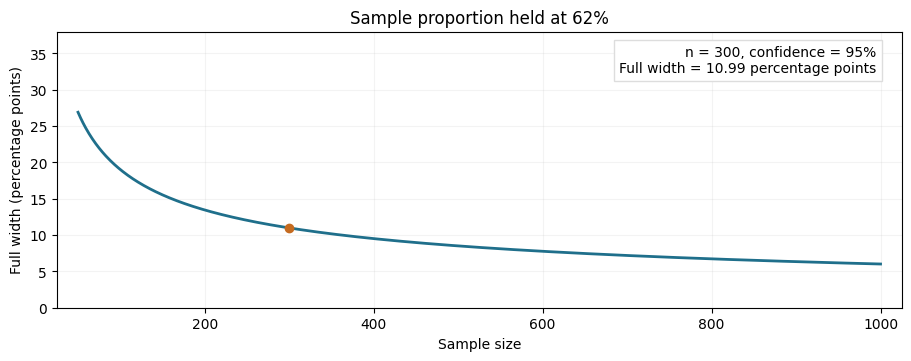

$$\hat p=\frac{186}{300}=0.62,\qquad E=z_{\alpha/2}\sqrt{\frac{\hat p(1-\hat p)}{n}}\approx 1.960\sqrt{\frac{0.62(0.38)}{300}}\approx 0.0549.$$

The 95% confidence interval is $[0.5651,\,0.6749]$.

In [4]:
import ipywidgets as widgets
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display
from scipy.stats import norm


def proportion_interval_explorer():
    display(Markdown("### Confidence Level and Proportion Interval Width"))
    style = {"description_width": "initial"}
    sample_size = widgets.IntSlider(
        value=300, min=50, max=1000, step=50, description="Sample size:",
        continuous_update=False, style=style
    )
    confidence_level = widgets.Dropdown(
        options=[("90%", 0.90), ("95%", 0.95), ("99%", 0.99)],
        value=0.95, description="Confidence level:", style=style
    )
    display(widgets.HBox([sample_size, confidence_level]))
    graph_handle = text_handle = None

    def update(change=None):
        nonlocal graph_handle, text_handle
        n, confidence = sample_size.value, confidence_level.value
        successes = 31 * (n // 50)
        p_hat = successes / n
        critical = norm.isf((1 - confidence) / 2)
        margin = critical * np.sqrt(p_hat * (1 - p_hat) / n)
        lower, upper = p_hat - margin, p_hat + margin
        sizes = np.arange(50, 1001)
        widths = 200 * critical * np.sqrt(p_hat * (1 - p_hat) / sizes)

        fig, ax = plt.subplots(figsize=(9, 3.5), constrained_layout=True)
        ax.plot(sizes, widths, color="#1f6f8b", linewidth=2)
        ax.scatter(n, 200 * margin, color="#c56b20", zorder=3)
        ax.text(0.97, 0.95, f"n = {n:,}, confidence = {confidence:.0%}\n"
                f"Full width = {200 * margin:.2f} percentage points",
                transform=ax.transAxes, ha="right", va="top",
                bbox={"facecolor": "white", "edgecolor": "#dddddd"})
        ax.set(title="Sample proportion held at 62%",
               xlabel="Sample size", ylabel="Full width (percentage points)",
               xlim=(25, 1025), ylim=(0, 38))
        ax.grid(alpha=0.15)
        if graph_handle is None:
            graph_handle = display(fig, display_id=True)
        else:
            graph_handle.update(fig)
        plt.close(fig)

        content = Markdown(
            rf"$$\hat p=\frac{{{successes}}}{{{n}}}=0.62,\qquad "
            rf"E=z_{{\alpha/2}}\sqrt{{\frac{{\hat p(1-\hat p)}}{{n}}}}"
            rf"\approx {critical:.3f}\sqrt{{\frac{{0.62(0.38)}}{{{n}}}}}"
            rf"\approx {margin:.4f}.$$"
            "\n\n"
            rf"The {100 * confidence:.0f}% confidence interval is "
            rf"$[{lower:.4f},\,{upper:.4f}]$."
        )
        if text_handle is None:
            text_handle = display(content, display_id=True)
        else:
            text_handle.update(content)

    for control in (sample_size, confidence_level):
        control.observe(update, names="value")
    update()
    return sample_size, confidence_level


proportion_interval_controls = proportion_interval_explorer()


---

### Exercise 4

Eta Support monitors the proportion of tickets resolved on the first contact. A random sample of independent tickets gives the following counts.

| Tickets sampled | Resolved on first contact |
|---:|---:|
| 400 | 218 |

a. Calculate a 95% confidence interval for the population proportion resolved on the first contact. Does it include 50%?

b. A colleague reports that both a 90% and a 95% confidence interval give the same conclusion about whether 50% is inside the interval. Check the claim using the same sample.

---


### Sample Size for Estimating a Proportion

Set a target margin of error $E_0$ and choose a planning proportion $p_0$ before sampling.

$$E_{\text{plan}}=z_{\alpha/2}\sqrt{\frac{p_0(1-p_0)}n}.$$

Require $E_{\text{plan}}\leq E_0$. Squaring both sides and solving for $n$ gives

$$\frac{z_{\alpha/2}^2p_0(1-p_0)}n\leq E_0^2
\quad\Longrightarrow\quad
n\geq\frac{z_{\alpha/2}^2p_0(1-p_0)}{E_0^2}.$$

* Round up to a whole observation.
* Express the target in proportion units. Four percentage points corresponds to $E_0=0.04$.
* Calculate the reported interval with the observed $\hat p$ once the sample is collected.

---


### Planning Proportion

* Use a recent, comparable estimate or a pilot sample when available.
* With no suitable estimate, use $p_0=0.50$.

$$p_0(1-p_0)=0.25-(p_0-0.50)^2\leq0.25.$$

The required sample size is largest at $p_0=0.50$. Planning with this value gives a sample size that meets the margin-of-error target for any observed $\hat p$ under the interval formula.

| Planning proportion $p_0$ | $p_0(1-p_0)$ |
|---:|---:|
| 0.20 | 0.16 |
| 0.50 | 0.25 |
| 0.80 | 0.16 |

The planning choice affects the sample size. The observed counts still determine whether the normal approximation is appropriate.

---


### Sample Size for On-Time Dispatch

Zeta Distribution plans a new study. It wants 95% confidence with a margin of error of at most four percentage points. Its previous estimate was 0.62.

$$n\geq\frac{z_{\alpha/2}^2p_0(1-p_0)}{E_0^2},
\qquad z_{0.025}=1.96,\quad E_0=0.04.$$

| Planning choice | Sample-size calculation | Minimum sample size |
|---|---|---:|
| Comparable previous estimate, $p_0=0.62$ | $\dfrac{1.96^2(0.62)(0.38)}{0.04^2}=565.6756$ | 566 |
| Conservative choice, $p_0=0.50$ | $\dfrac{1.96^2(0.50)(0.50)}{0.04^2}=600.25$ | 601 |

The conservative plan requires 35 additional dispatches. The smaller plan meets the planning target at $p_0=0.62$, but the reported margin of error can be larger if the new sample proportion is closer to 0.50.

---


### Exercise 5

Theta Retail is estimating the proportion of online orders returned. The previous return rate was 20%, but a new return policy may have changed it. Orders can be sampled independently.

| Confidence level | Target margin of error | Maximum sample size |
|---:|---:|---:|
| 95% | 4 percentage points | 450 orders |

a. Find the minimum sample size for each planning approach below. In each case, are 450 orders enough?

* Use the previous return rate of 20% as the planning estimate.
* Plan for a margin of error of at most four percentage points for any sample return rate.

b. The retailer samples 450 orders, and 144 are returned. Did the study achieve the requested precision at 95% confidence? Explain why this outcome is consistent with part (a).

---


### Confidence Intervals for a Finite Population

For a simple random sample without replacement, use the finite-population correction when $n/N>0.05$. For a proportion, apply it to the estimated standard error.

$$E=z_{\alpha/2}\sqrt{\frac{\hat p(1-\hat p)}n}
\sqrt{\frac{N-n}{N-1}}.$$

A warehouse audits a simple random sample of 100 of its 500 orders from last month. Of those audited, 65 met the dispatch target.

$$\hat p=\frac{65}{100}=0.65,\qquad
\frac nN=\frac{100}{500}=0.20.$$

$$E=1.96\sqrt{\frac{0.65(0.35)}{100}}\sqrt{\frac{500-100}{500-1}}
\approx0.0837.$$

* The approximate 95% confidence interval is $0.65\pm0.0837$, or $[0.5663,\,0.7337]$. 
* It estimates the proportion for last month's 500 orders.

---


### Planned and Observed Margin of Error

Iota Logistics plans a 95% confidence interval for mean loading time. A pilot study suggests $\sigma_{\text{plan}}=3$ minutes. The target margin of error is 1 minute.

$$n\geq\left(\frac{z_{\alpha/2}\sigma_{\text{plan}}}{E_0}\right)^2
=\left(\frac{1.96(3)}{1}\right)^2=34.5744.$$

The company samples 35 independent loading times. The observed standard deviation is $s=3.6$ minutes. With $df=34$, $t_{0.025}\approx2.032$.

$$E=t_{\alpha/2}\frac{s}{\sqrt n}
=2.032\frac{3.6}{\sqrt{35}}\approx1.24\text{ minutes}.$$

* The reported margin exceeds the 1-minute target. 
* The observed standard deviation is higher than the planning value, and the $t$ critical value is larger than the $z$ value used to plan the study.

---


### Big Data and Confidence Intervals

For a fixed confidence level and standard deviation, the usual margin of error decreases with $1/\sqrt n$.

$$E=z_{\alpha/2}\frac{\sigma}{\sqrt n}.$$

| Independent observations | 95% margin of error with $\sigma=20$ |
|---:|---:|
| 100 | $1.96(20)/\sqrt{100}=3.92$ |
| 10,000 | $1.96(20)/\sqrt{10{,}000}=0.392$ |

* A larger random sample can greatly reduce sampling variability.
* A company that uses only app transactions to estimate spending across all customers misses those who shop exclusively in person. Adding app transactions does not fill that gap.
* Repeated transactions by the same customer may be dependent. Treating them as independent can make the calculated standard error too small.

---


### Confidence Intervals in Excel

| Example | Center | Formula for the margin of error |
|---|---:|---|
| Mean fill volume, $\sigma$ known | 497.8 mL | `=CONFIDENCE.NORM(0.05,12,36)` |
| Mean service time, $\sigma$ unknown | 12 minutes | `=CONFIDENCE.T(0.05,2,8)` |
| Proportion of dispatches on time | $186/300=0.62$ | `=NORM.S.INV(1-0.05/2)*SQRT(0.62*(1-0.62)/300)` |

* In the first two functions, enter the total tail area $\alpha$, the standard deviation, and the sample size.
* Calculate the endpoints by subtracting and adding the returned margin of error.
* For sample-size calculations, use `ROUNDUP` after evaluating the formula. For example, `=ROUNDUP((1.96*12/2)^2,0)` gives 139 bottles.

---


### Exercise 6

Kappa Wholesale is reviewing the proportion of last month's orders that shipped within one day. It will revise its process only if the entire 95% interval lies below its fixed target of 69%.

| Orders last month | Orders selected by simple random sampling without replacement | Sampled orders shipped within one day |
|---:|---:|---:|
| 400 | 100 | 60 |

a. Calculate an approximate 95% confidence interval for the proportion of last month's orders that shipped within one day.

b. A colleague omits the finite-population correction. Would that change the decision under the company's rule? Show both conclusions.

---


### Interval Estimation Summary

The table uses standard errors for independent random samples.

| Population parameter | Center | Standard error used | Critical value |
|---|---:|---:|---:|
| Mean, $\sigma$ known | $\bar x$ | $\sigma/\sqrt n$ | $z_{\alpha/2}$ |
| Mean, $\sigma$ unknown | $\bar x$ | $s/\sqrt n$ | $t_{\alpha/2}$ with $df=n-1$ |
| Proportion | $\hat p$ | $\sqrt{\hat p(1-\hat p)/n}$ | $z_{\alpha/2}$ |

$$\text{Confidence interval}=\text{estimate}\pm
\text{critical value}\times\text{standard error}.$$

* Check the sampling method and the conditions for the selected interval.
* For a fixed confidence level, the planned sample size depends on the target margin of error and the anticipated variability.
* Report the endpoints, the confidence level, and the population quantity being estimated.

---


### What is next?

* Hypothesis Testing
  * Null and alternative hypotheses
  * Type I and Type II errors
  * Tests for a population mean and a population proportion

Reading(s): SBE Sections 9.1–9.5

---


### Exercise 7

Lambda Support reviews both the average resolution time and the proportion of tickets resolved within 45 minutes. A random sample of independent tickets gives the following results. Assume the population distribution of resolution time is approximately normal.

| Tickets sampled | Mean time | Sample SD | Tickets resolved within 45 minutes |
|---:|---:|---:|---:|
| 25 | 43 minutes | 6 minutes | 18 |

Management wants an average below 46 minutes and at least 60% of tickets resolved within 45 minutes. It will count a target as supported if the whole corresponding 95% interval is on the required side of the benchmark.

* Which targets are supported? 

* Give an interval for each and explain whether the results justify saying both requirements have been met.

---


### Exercise 8

Mu Telecom wants to know whether a majority of current subscribers would switch to a new billing plan. It obtains two sets of responses.

| Method | Respondents | Would switch |
|---|---:|---:|
| Random sample from the full subscriber list, with all selected subscribers responding | 400 | 212 |
| Voluntary poll shown only to subscribers using the mobile app | 10,000 | 6,200 |

a. Calculate the interval each method would report if it used the usual 95% proportion formula. The subscriber population is large compared with both samples.

b. A director proposes announcing that most current subscribers would switch. Would you make the announcement? Use the estimates, intervals, and sampling methods to justify your decision.

---


### Exercise 9

Nu Packaging will sample independent packages. Each sampled package is weighed and inspected for label defects.

| Quantity to estimate | Planning information | Precision target |
|---|---|---|
| Mean package weight | Known population SD of 0.90 kg | Full interval width of at most 0.20 kg |
| Proportion with label defects | No suitable prior estimate | Margin of error of at most 5 percentage points |

Use 95% confidence for each interval.

a. Find the smallest number of packages to sample to meet both planning targets.

b. The inspection budget falls to 340 packages. At 95% confidence, find the planned full width for the mean interval and the conservative margin of error for the proportion interval. Which precision target would need to be relaxed?

---
